# 7.1 Interference and mutual coherence of two plane waves

**Why can overlapping beams produce bright and dark fringes instead of simply adding their brightnesses?**

**Medium and wavelength convention.** The interferometer's surrounding medium is air, approximated by $n=1$; its 632.8 nm input is used as the propagation wavelength in that approximation. Air dispersion and the small air–vacuum wavelength difference are omitted. The EO element's voltage-controlled material index supplies a prescribed phase shift; it does not change the ambient wavelength or wavevector directions in this model. See the [course medium convention](0_0_Foundations_of_Scalar_Optics.ipynb#medium-and-wavelength).

**Chapter overview:** [7.0: Introduction to interference and beam overlap](7_0_Introduction_to_Interference_and_Beam_Overlap.ipynb).

## Motivation

Split a laser beam and recombine its two paths at a camera. Observe interference, connect fringe contrast to field correlation, and use EO phase control to distinguish moving fringes from reducing coherence.

## Prerequisites

Continue from [Chapter 6: amplitude and intensity](6_0_Amplitude_and_Intensity_of_a_Scalar_Wave.ipynb), especially [6.1: time averaging](6_1_Time_Averaging_and_Relative_Intensity.ipynb) and [6.2: a detector plane](6_2_One_Order_Across_a_Detector.ipynb). Recall complex fields and wavevectors. We retain $e^{-i\omega t}$ and relative scalar intensity $I_{\mathrm{rel}}=|U|^2$ (reference amplitude set to one); below we write $I$ for this normalized quantity.

Run cells in order; no previous notebook needs to be run. The experimental views share geometry controls; the small calculations use their own written values. **Next:** [7.2](7_2_Interference_of_Diffraction_Orders_from_a_Grating.ipynb).


### From ideal plane waves to finite optical beams

[1.2](1_2_Ideal_Plane_Waves_versus_Finite_Optical_Beams.ipynb) distinguishes an ideal plane wave,

$$U(\mathbf{r})=A_0e^{i\mathbf{k}\cdot\mathbf{r}},$$

from a finite beam with a spatial envelope and phase,

$$U(\mathbf{r})=A(\mathbf{r})e^{i\Phi(\mathbf{r})}.$$

Where its wavefronts are nearly planar, a central wavevector gives the local approximation

$$U(\mathbf{r})\approx A(\mathbf{r})e^{i\mathbf{k}_c\cdot\mathbf{r}}.$$

| Ideal plane-wave components | Finite beams in this notebook |
| --- | --- |
| Constant amplitude; indefinite extent | Spatially varying envelope |
| One exact wavevector | Approximate central wavevector |
| Overlap throughout the modeled region | Appreciable overlap must be arranged |

- The model uses Gaussian envelopes with locally planar phases, not exact diffraction propagation.
- Gaussian tails have no sharp edge. Negligible overlap gives negligible observable interference.
- Contrast also depends on correlation and measurement conditions.

### Two classical ways to produce interfering optical fields

**Division of wavefront** samples different spatial portions of an incident wavefront. **Division of amplitude** splits an incident field into optical paths that are later recombined. Both obey the same field-superposition law. [\[1\]](#ref-7-1-toronto), [\[2\]](#ref-7-1-mit-interferometers), [\[3\]](#ref-7-1-unisciel)

| Property | Wavefront division | Amplitude division |
| --- | --- | --- |
| Classical example | Young’s double slit | Michelson interferometer |
| How fields overlap | Fields from separate openings spread and overlap | Split paths are redirected and recombined |
| Typical coherence sensitivity | Spatial sampling and slit separation | Temporal delay and optical path difference |
| Course example | Two separated openings sampling one wavefront | **7.1: this experiment** |

These sensitivities are not exclusive: path delay, source extent, spatial mismatch and averaging can matter in either category. Mutual coherence describes the actual fields being compared. [\[4\]](#ref-7-1-delft-coherence)

**History.** Young established wavefront-division interference; his 1804 account used a narrow card. Michelson developed amplitude-division interferometers. Van Cittert, Zernike and Wolf later connected visibility with field correlation. [\[5\]](#ref-7-1-young-1804), [\[6\]](#ref-7-1-nobel), [\[7\]](#ref-7-1-michelson), [\[8\]](#ref-7-1-gbur-visser), [\[9\]](#ref-7-1-parrent), [\[10\]](#ref-7-1-mandel-wolf)

:::{dropdown} Optional: path delay and coherence length

Different optical path lengths introduce a delay. Visibility can fall when it exceeds the source’s coherence time. For narrowband light in air, $\ell_c\sim\lambda^2/\Delta\lambda$; its coefficient depends on spectral shape and the coherence-length definition. This monochromatic apparatus does not simulate finite linewidth or measure coherence length. [\[4\]](#ref-7-1-delft-coherence)

:::


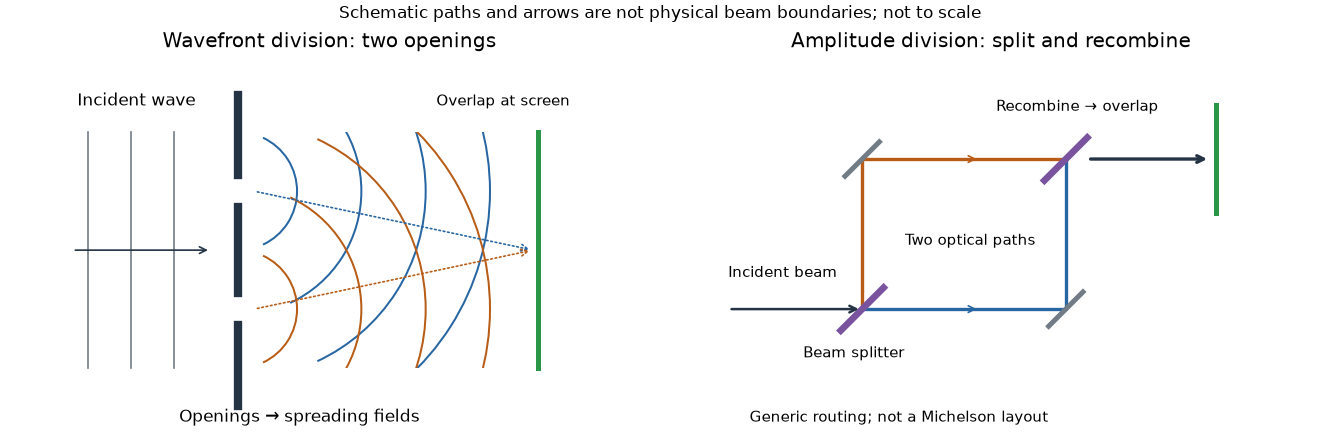

In [ ]:
from pathlib import Path
import sys
import importlib
from IPython.display import display

_support_dir = next((p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
    if (p / 'wave_optics' / '__init__.py').is_file()), None)
if _support_dir is None:
    raise FileNotFoundError('Open this notebook within the Grating_Physics folder.')
if str(_support_dir) not in sys.path:
    sys.path.insert(0, str(_support_dir))
importlib.invalidate_caches()
if 'wave_optics' in sys.modules:
    sys.modules['wave_optics'].__path__[:] = [str(_support_dir / 'wave_optics')]

for previous in globals().get('interference_lessons', {}).values():
    previous.close()

from wave_optics.mutual_coherence_view import (
    MutualCoherenceExplorer, ExperimentalInterferometer, ExperimentalEOView)
interference_lessons = {}

def show_visibility():
    if 'visibility' in interference_lessons:
        interference_lessons['visibility'].close()
    lesson = MutualCoherenceExplorer('visibility')
    interference_lessons['visibility'] = lesson
    display(lesson.ui)


## 1. Experimental setup: split, redirect and overlap

**This is an amplitude-division experiment.** A beam splitter divides a finite-width laser beam; a mirror redirects one path so both fields overlap at the detector. The arrangement illustrates the principle without being an exact Michelson interferometer.

The splitter is the origin, the mirror is along positive $x$, and the detector is an $xy$ plane at $z_D<0$. Both arriving beams propagate toward decreasing $z$. The wavelength is $632.8$ nm; common $y$ polarization permits a scalar model.

**Try it:** change mirror tilt to change the crossing angle, then move the detector with tilt fixed. Does moving the camera change propagation directions or only the sampled overlap? Reset afterward.

Positive mirror tilt decreases the crossing angle by twice the mirror rotation. More negative $z_D$ places the detector farther from the splitter. These shared controls update the later figures. Beam specifications and overlap calculations are optional. [\[11\]](#ref-7-1-catunda)


In [ ]:
for key in ('phase', 'experiment'):
    if key in interference_lessons:
        interference_lessons.pop(key).close()
interference_lessons['experiment'] = ExperimentalInterferometer()
display(interference_lessons['experiment'].ui)

:::{dropdown} What changes when the detector moves?

Beam directions and crossing angle stay fixed. The detector samples a different slice through the finite beams, changing their local intensities and overlap. Reset restores tilt and detector position.

:::


## 2. Wavefronts and detector interference

Select either signed field, then **Combined intensity**. Rotate the wavefront view and compare the resolved detector patch with the full-detector overview. Signed fields can be negative; intensity cannot.

**Try it:** change mirror tilt, then move the detector with tilt fixed. Which changes fringe spacing? For tilt $+2^\circ$, a detector position near $-9.15$ restores centred overlap. Watch the vector inset, then reset.


In [ ]:
display(interference_lessons['experiment'].detector_ui)

Each beam has a wavevector, $\mathbf k_1$ or $\mathbf k_2$, pointing along propagation. At position $\mathbf r$, their difference, $\Delta\mathbf k$, determines how the relative phase varies across space. The relative phase, $\Delta\Phi$, is beam 2's phase minus beam 1's; $\Delta\phi_0$ is their constant phase offset:

$$\Delta\mathbf k=\mathbf k_2-\mathbf k_1,\qquad
\Delta\Phi(\mathbf r)=\Delta\mathbf k\cdot\mathbf r+\Delta\phi_0.$$

The inset's tip-to-tip arrow is this difference. Its detector-plane projection points across the fringes; constant relative phase traces a fringe. Changing a constant phase offset moves the stripes without changing their spacing. At fixed tilt, moving a parallel detector preserves both wavevectors and the spacing. Tilting the mirror changes them. [\[11\]](#ref-7-1-catunda)

Here the wavenumber is $k=2\pi/\lambda$, where $\lambda$ is wavelength, and the full crossing angle is $\theta$. The beam directions give $\mathbf k_1=k(0,0,-1)$ and $\mathbf k_2=k(-\sin\theta,0,-\cos\theta)$. The period across $x$ is $\lambda/|\sin\theta|$, about $2.17\,\mu\mathrm m$ at default tilt.

For equal-frequency plane waves, let $A_j$ be each nonnegative field amplitude and $\phi_j$ its phase offset. The complex field of beam $j$ is $U_j=A_je^{i(\mathbf k_j\cdot\mathbf r+\phi_j)}$. **Fields add first:** squaring their sum gives $I=A_1^2+A_2^2+2A_1A_2\cos\Delta\Phi$. The last term can reinforce or cancel the individual intensities.
- Equal amplitudes permit a dark minimum; unequal amplitudes leave residual light.

### Small calculation 1: add fields before squaring

At one detector point, use field amplitudes 1 and 1, with beam 2 initially $60^\circ$ ahead. **Predict:** does the total intensity equal the sum of the separate intensities? The complex exponential represents a phase rotation; squared magnitude calculates relative intensity. Run the calculation, then change `relative_phase_deg` to 180 and finally 90.
- Interpret the cross term in each case.

In [ ]:
import numpy as np

relative_phase_deg = 60.0  # change to 180, then 90; independent of sliders
field_1 = 1.0 + 0j
field_2 = np.exp(1j*np.deg2rad(relative_phase_deg))
separate_intensity = np.abs(field_1)**2 + np.abs(field_2)**2
summed_field_intensity = np.abs(field_1 + field_2)**2
cross_term = 2*np.real(np.conj(field_1)*field_2)
print(f'Separate intensities added: {separate_intensity:.3f}')
print(f'Intensity of summed field: {summed_field_intensity:.3f}')
print(f'Interference cross term: {cross_term:+.3f}')

:::{dropdown} Answer: starting values and phase changes

The separate intensities always add to 2. At $60^\circ$, the cross term is ${+1}$ and the total is 3. At $180^\circ$, the cross term is ${-2}$ and the total is zero: equal fields cancel. At $90^\circ$, the cross term vanishes and the total is 2, despite full coherence. Agreement with intensity addition at this one phase does not establish incoherence. Tiny numerical residuals at exact cancellation are floating-point rounding.

:::

## 3. Mutual coherence and fringe visibility

**Visibility describes the observed pattern; mutual coherence describes field correlation.** To connect them, specify what the detector averages. This distinction explains why weak contrast need not imply weak intrinsic coherence.


Let $U_1$ and $U_2$ be the arriving complex fields at one detector point, with the common optical oscillation suppressed. A camera averages squared field amplitude over many optical cycles. Slower changes may occur during the exposure. Brackets $\langle\cdot\rangle$ denote that observation average, or an ensemble average representing it. We average intensities and complex products, not the signed optical oscillation.

The mean intensity of either arm alone is $\bar I_j=\langle|U_j|^2\rangle$. The **mutual coherence**, denoted $\Gamma_{12}$, averages the conjugated first field times the second. The star means complex conjugation. Dividing by the arm-intensity scale defines the complex **degree of mutual coherence**, $\gamma_{12}$:

$$\Gamma_{12}=\langle U_1^*U_2\rangle,\qquad
\gamma_{12}=\frac{\Gamma_{12}}{\sqrt{\bar I_1\bar I_2}}.$$

This normalized correlation has magnitude between zero and one when both arms are nonzero. A reproducible field relationship can survive averaging; phase-varying products can partly cancel. If either arm is dark, the normalized quantity is undefined. Expanding the squared sum gives the averaged interference law; $\operatorname{Re}$ means real part:

$$\bar I=\langle|U_1+U_2|^2\rangle
=\bar I_1+\bar I_2+2\operatorname{Re}\Gamma_{12}
=\bar I_1+\bar I_2+2\sqrt{\bar I_1\bar I_2}\operatorname{Re}\gamma_{12}.$$

The mean arm intensities alone cannot supply the cross term. Its surviving value depends on field correlation. The steady monochromatic apparatus assumes full mutual coherence; the compact comparison below prescribes a correlation magnitude to explore the more general averaged law. [\[8, §§2–3\]](#ref-7-1-gbur-visser), [\[10\]](#ref-7-1-mandel-wolf)

Writing $I_j=\bar I_j$ and $I=\bar I$ for these averaged intensities, the same law becomes

$$I=I_1+I_2+2\sqrt{I_1I_2}|\gamma_{12}|\cos\delta.$$

Here $\delta=\arg\gamma_{12}$ is the relevant fringe phase for the actual arriving fields, including propagation and fixed phase shifts under our convention. Do not add those phases twice. If correlation vanishes, its phase is undefined and the cross term is zero. This law applies to both experimental categories.


To measure **visibility**, scan phase while holding local arm intensities and coherence magnitude fixed. Call the largest and smallest averaged readings $\bar I_{\max}$ and $\bar I_{\min}$. Their normalized contrast is

$$V=\frac{\bar I_{\max}-\bar I_{\min}}{\bar I_{\max}+\bar I_{\min}}
=\frac{2\sqrt{\bar I_1\bar I_2}}{\bar I_1+\bar I_2}|\gamma_{12}|.$$

The same formula applies locally across spatial fringes if beam envelopes change little over one period. Visibility equals coherence magnitude only for equal local intensities under these measurement assumptions. Unequal intensities reduce it even for fully coherent fields. [\[8, §3\]](#ref-7-1-gbur-visser)

In the comparison, reduce prescribed coherence at balanced intensities, reset, then change only intensity ratio. Both reduce contrast. Its prescribed correlation is defined before the spatial phase factor; the arriving-field definition above already includes propagation phase.

For the experimental detector:

Separated footprints change the local intensity balance. Finite image bins can average unresolved stripes. Neither effect establishes lower intrinsic source coherence.
- To infer coherence from visibility, control intensity balance, polarization, overlap, resolution and exposure. This apparatus does not measure the laser's coherence time.

In [ ]:
show_visibility()

### Small calculation 2: the same visibility, different causes

Compare mean intensity pairs $(1,1)$ and $(1,4)$ at full coherence, then $(1,1)$ at coherence magnitude $0.5$. **Predict:** which case has the greatest visibility? Run the formula below. Change the final magnitude from `0.5` to `0.8`: can equal and unequal beams now give the same measured visibility?
- The square root supplies the intensity-balance factor; it does not estimate coherence from brightness alone.

In [ ]:
cases = [('balanced, coherent', 1.0, 1.0, 1.0),
         ('unequal, coherent', 1.0, 4.0, 1.0),
         ('balanced, partial', 1.0, 1.0, 0.5)]  # change final 0.5 to 0.8
visibility_results = []
for label, i1, i2, coherence_magnitude in cases:
    visibility = 2*np.sqrt(i1*i2)/(i1+i2)*coherence_magnitude
    visibility_results.append(visibility)
    print(f'{label}: V = {visibility:.3f}')

:::{dropdown} Answer: coherence and balance are separate factors

The starting visibilities are 1, 0.8 and 0.5. Balanced, fully coherent fields have the greatest modulation. Changing the last coherence magnitude to 0.8 gives visibility 0.8, matching the unequal but fully coherent case. A contrast measurement alone cannot distinguish those situations. Separate arm-intensity measurements, together with a controlled averaging procedure, are needed before inferring coherence magnitude.

:::

## 4. EO phase control: translation is not decorrelation

An ideal **electro-optic (EO) phase modulator** adds phase to beam 2 through a voltage-controlled refractive index, preserving direction and intensity. This view shares Section 1’s geometry. [\[12\]](#ref-7-1-thorlabs)

**Try it:** hold geometry fixed and change EO phase from zero to $180^\circ$. Bright and dark stripes exchange places, but spacing and phase-scan visibility stay fixed. A pixel becoming dark is not the whole pattern losing contrast.


In [ ]:
if 'phase' in interference_lessons:
    interference_lessons['phase'].close()
interference_lessons['phase'] = ExperimentalEOView(interference_lessons['experiment'])
display(interference_lessons['phase'].ui)

Let $\beta$ denote the additional fixed EO phase. Because arm 1 is conjugated in our correlation definition, multiplying arm 2 by $e^{i\beta}$ gives

$$U_2\rightarrow U_2e^{i\beta},\qquad
\gamma_{12}\rightarrow\gamma_{12}e^{i\beta},\qquad
|\gamma_{12}|\text{ remains unchanged}.$$

**Changing relative phase and changing mutual-coherence magnitude are different physical operations.** A constant phase rotates the complex correlation without shortening it, including for a partially coherent pair if the shift is fixed throughout averaging.

If phase instead switches during an unresolved exposure, the detector averages different patterns. That can reduce the relevant exposure-averaged correlation, although each resolved setting is fully coherent. The optional panel demonstrates this separate averaging experiment. Specify whether phase is held fixed, resolved in time, or mixed within one measurement.

### Small calculation 3: rotate a correlation without shortening it

Use reference coherence magnitude $0.6$ and phase $30^\circ$; add an EO shift of $90^\circ$. **Predict:** what happens to magnitude and phase? The spatial period is $2.17\,\mu\mathrm m$ and the experimental phase gradient across $x$ is negative. Run the code, then change `eo_phase_deg` to 180.
- The displacement is measured along positive $x$ for the same tracked fringe, modulo a full period.

In [ ]:
reference_gamma = 0.6*np.exp(1j*np.deg2rad(30.0))
eo_phase_deg = 90.0  # change to 180
shifted_gamma = reference_gamma*np.exp(1j*np.deg2rad(eo_phase_deg))
period_um = 2.17
phase_gradient = -2*np.pi/period_um  # experimental Delta k_x, rad/um
fringe_shift_um = -np.deg2rad(eo_phase_deg)/phase_gradient
print(f'Coherence magnitudes: {np.abs(reference_gamma):.3f}, {np.abs(shifted_gamma):.3f}')
print(f'Coherence phases (degrees): {np.angle(reference_gamma, deg=True):.1f}, '
      f'{np.angle(shifted_gamma, deg=True):.1f}')
print(f'Fringe displacement along x: {fringe_shift_um:+.4f} um')

:::{dropdown} Answer: a phase rotation moves the fringes

At $90^\circ$, both magnitudes are 0.6, while the reference coherence phase changes from $30^\circ$ to $120^\circ$. The displacement is $+0.5425\,\mu\mathrm m$, a quarter period. At $180^\circ$, the magnitude remains 0.6 and displacement is $+1.0850\,\mu\mathrm m$, half a period. NumPy reports the new phase as $-150^\circ$, equivalent to $210^\circ$.

A tracked fringe satisfies $\Delta k_x\Delta x+\beta=0$, hence $\Delta x=-\beta/\Delta k_x$. Our negative phase gradient makes a positive EO shift move it toward positive $x$. The calculation uses a representative rounded period; the interactive detector retains its full experimental geometry. Neither rotation changes coherence magnitude.

:::

## Final checkpoint

1. Why can two ideal plane waves overlap everywhere in the modeled region, while two finite laser beams may require mirrors to create an observable interference region?
2. What information about the fields does mutual coherence add beyond their individual mean intensities?
3. Can fully coherent beams have weak measured visibility? Give two experimental reasons.
4. When EO phase changes but geometry stays fixed, what happens to fringe position and spacing?
5. Does a fixed phase shift reduce coherence magnitude? How would you test that claim?
6. Why can one unresolved exposure differ from a time-resolved view of the same switching beams?
7. How does division of wavefront differ from division of amplitude, and which method is used in this notebook?
8. Why is spatial coherence particularly important in Young’s double-slit experiment, while temporal coherence is often important in a Michelson interferometer?

:::{dropdown} Checkpoint answers

1. Ideal plane waves have no finite transverse boundaries. Finite beams have spatial envelopes, so their fields must overlap appreciably for visible interference. Mirrors can redirect separated beams into a common region. Gaussian tails can make the mathematical overlap nonzero even when it is too weak to observe.
2. Mutual coherence averages the conjugated product of the two fields under the stated observation. It describes correlation that separate intensities do not specify; its normalized magnitude removes the overall intensity scale.
3. Unequal local intensities reduce visibility even at unit coherence magnitude. Averaging unresolved bright and dark stripes within detector bins can also reduce recorded contrast without altering field coherence.
4. A fixed EO phase translates fringes. Spacing is unchanged because the wavevector difference stays fixed; local phase-scan visibility also stays fixed under the model assumptions.
5. No. Compare the magnitude of the complex correlation before and after multiplication by a unit-magnitude phase factor. This rotates the correlation, including when its initial magnitude is below one. If it is zero, its phase is undefined.
6. An unresolved exposure averages the intensities of different phase settings, which can cancel their modulations. A resolved view retains each setting's fringes. The averaged correlation must refer to the same averaging procedure as the recorded intensity.
7. Wavefront division samples different spatial portions of an incident wavefront; amplitude division splits a field into optical paths. This notebook uses amplitude division. Both follow the same field-superposition law.
8. Young’s openings compare different spatial samples, so their separation probes spatial correlation. Unequal Michelson arm delays compare emission at different times, probing temporal correlation. These are typical sensitivities: path delay can matter in wavefront division, and source extent, overlap and angular averaging can matter in amplitude division. Neither category is restricted to one coherence limitation.

:::

Fields add before squaring; their averaged cross term depends on mutual coherence. Visibility also depends on intensity balance and detector averaging. A fixed EO phase shifts fringes without reducing coherence magnitude.

<a id="next-lesson"></a>

**Next:** [7.2: interference of diffraction orders](7_2_Interference_of_Diffraction_Orders_from_a_Grating.ipynb). Distinguish interference between contributions from different openings from interference between already-formed diffraction orders. These are different choices of field contributions under the same superposition law. Return to [Chapter 6](6_0_Amplitude_and_Intensity_of_a_Scalar_Wave.ipynb) for the intensity convention.


:::{dropdown} Optional: laser specifications and finite-beam assumptions

The original experimental example uses a continuous-wave laser with wavelength $632.8\,\mathrm{nm}$, output power $1\,\mathrm{mW}$ and output $1/e^2$ intensity diameter $0.54\,\mathrm{mm}$. The laser specification source is listed below; its output diameter is separate from the assumed crossing diameter. The diameter describes a Gaussian contour, not a sharp edge, and the output diameter need not equal the diameter at the beam crossing.

Separately assume equal, constant crossing diameters $D_c=0.54\,\mathrm{mm}$, ideal 50:50 splitting, a lossless mirror and a fixed relative reflection/transmission phase of zero. One schematic length unit represents $1.8\,\mathrm{mm}$. The detector is a $2.34\,\mathrm{mm}$ square. These assumptions set the model, rather than calibrating a particular camera.

The detector uses $I_j(\rho_j)=I_{\mathrm{peak}}\exp(-2\rho_j^2/w^2)$ with $w=D_c/2$. Widths and planar phase fronts stay fixed; spreading and curvature are omitted. One intensity unit is the default on-axis intensity of either arm. Plot ranges and this reference stay fixed while controls move. The full-detector overview includes finite-bin averaging; the small patch resolves the fringes.

Sources: [\[11\]](#ref-7-1-catunda), [\[13\]](#ref-7-1-newport-hene).

:::

:::{dropdown} Optional: overlap volume and the detector slice

Replace the finite-width contours by two long circular cylinders of equal radius $R=D_c/2$, crossing at full angle $\theta$. At height $y$ perpendicular to the axes' plane, each cylinder occupies a strip of half-width $\sqrt{R^2-y^2}$. The strips' intersection is a parallelogram. Integrating its area gives

$$V_{\mathrm{overlap}}=\int_{-R}^{R}\frac{4(R^2-y^2)}{|\sin\theta|}\,dy
=\frac{16R^3}{3|\sin\theta|}=\frac{2D_c^3}{3|\sin\theta|}.$$

The cylinders must extend through the complete intersection and must not be parallel. The divergence as the angle approaches zero reflects this idealization. Gaussian tails extend beyond the chosen contour, so this is a geometric estimate rather than a sharply bounded optical interaction volume.

At default tilt, $\theta\approx16.93^\circ$ gives $V_{\mathrm{overlap}}\approx0.361\,\mathrm{mm}^3$. Tilting the mirror changes this estimate. Moving the detector at fixed tilt changes the sampled two-dimensional slice, not the overlap volume.

Source for the equal-cylinder geometry: [\[14\]](#ref-7-1-hubbell).

:::

:::{dropdown} Optional: apparatus phase and path geometry

For splitter-to-mirror separation $h$, the original path construction gives

$$\Delta\phi_0=kh(1+\sin\theta)+\Delta\phi_{\mathrm{optics}},\qquad
\Delta\Phi(x,y,z_D)=k[-x\sin\theta+z_D(1-\cos\theta)]+\Delta\phi_0.$$

All lengths in these phase expressions must use the same units as $k$. Positive mirror tilt $\delta$ decreases the full crossing angle according to $\theta=\theta_0-2\delta$. Moving the detector changes the constant phase across its plane and the beam overlap, while leaving fringe spacing fixed at a given tilt. Mirror tilt changes the directions and the path-phase offset together.

Open the original path-geometry widget below to trace these contributions. It initializes its illustration only when expanded. No separate geometry model is introduced.

:::

In [ ]:
display(interference_lessons['experiment'].apparatus.phase_geometry_ui)

:::{dropdown} Optional: EO switching during an unresolved exposure

Open **Optional: phase changes during exposure** beneath the EO detector. Set the EO slider to $180^\circ$ and press Play. The resolved state alternates between two fully coherent patterns; the other panel shows their completed equal-time average. Bright and dark stripes exchange places, cancelling the averaged modulation. Playback is slowed for illustration; choosing a resolved state does not change the completed average.

With equal exposure weights at phases zero and $\beta$,

$$\gamma_{12}^{(\mathrm{exposure})}
=e^{i\Delta\Phi}\frac{1+e^{i\beta}}{2},\qquad
|\gamma_{12}^{(\mathrm{exposure})}|=\left|\cos\frac{\beta}{2}\right|.$$

At $90^\circ$ the magnitude is $1/\sqrt2$; at $180^\circ$ it vanishes. An exposure containing only one fixed setting preserves the steady coherence magnitude. Intensity imbalance still multiplies this factor when computing visibility.

The time-varying modulation deliberately changes the averaging experiment; it is no longer a single monochromatic field over the whole switching cycle. This demonstration does not determine the original laser's coherence time.

EO operating principle and time-varying sidebands: [\[12\]](#ref-7-1-thorlabs).

:::

:::{dropdown} Optional: execution and cleanup

Use NumPy, SciPy, Matplotlib, Plotly, ipywidgets and anywidget with a compatible Jupyter widget frontend. Restart the kernel after editing shared helpers. Repeating setup closes only this notebook's views; rerun later cells to recreate them. Repeating an individual display cell replaces its owned controls or reuses its existing figure. Repeating the apparatus cell also releases the dependent EO view, which must then be recreated. No global widget cleanup is used.

The apparatus reset restores mirror tilt and detector position together. The EO reset restores only fixed phase. The optional exposure panel has separate playback controls. To release all this notebook's views when finished:

:::

In [ ]:
# Optional cleanup when finished (leave commented to keep the figures interactive).
# for lesson in interference_lessons.values():
#     lesson.close()

## Worked-out examples

These optional scripts show the numerical implementation of the topics in this notebook.
Use the complete [scripts download](Downloads.md) to keep the plotting helper and
`wave_optics` package with the examples. Edit **INPUT PARAMETERS**, then run the file
or execute its `# %%` sections in order. Read **CHECK AND INTERPRET** with the plots.

### 1. Add fields before squaring

**Script:** [7_1_01_add_fields_before_squaring.py](Wave_solver_py_scripts/scripts/chapter_7/7_1_01_add_fields_before_squaring.py)

Evaluate the cross term in two-wave addition.

### 2. Mutual coherence and fringe visibility

**Script:** [7_1_02_ensemble_mutual_coherence.py](Wave_solver_py_scripts/scripts/chapter_7/7_1_02_ensemble_mutual_coherence.py)

Compute mutual coherence from a sampled phase ensemble.

### 3. The same visibility can have different causes

**Script:** [7_1_03_visibility_balance_and_coherence.py](Wave_solver_py_scripts/scripts/chapter_7/7_1_03_visibility_balance_and_coherence.py)

Separate amplitude imbalance from reduced mutual coherence.

### 4. EO phase control is not decorrelation

**Script:** [7_1_04_eo_phase_translation.py](Wave_solver_py_scripts/scripts/chapter_7/7_1_04_eo_phase_translation.py)

Translate fringes by rotating a complex correlation.






(refs-7-1)=

## References

(ref-7-1-toronto)=

[1] University of Toronto, *Interferometers*, laboratory manual. [Online]. Available: [PDF](https://www.physics.utoronto.ca/~phy293lab/experiments/interferometers.pdf).

**Reading notes:** §§1–2 and the Fabry–Pérot section: classical classification, amplitude division, optical paths and spectral sensitivity.

(ref-7-1-mit-interferometers)=

[2] MIT OpenCourseWare, *Mirrors, Interferometers and Thin-Film Structures*, secs. 2.3.6–2.3.7. [Online]. Available: [Mirrors, Interferometers and Thin-Film Structures, §§2.3.6–2.3.7](https://ocw.mit.edu/courses/6-974-fundamentals-of-photonics-quantum-electronics-spring-2006/98fcc94d2216c26db424e294c28d459a_mirror_inter_thn.pdf).

**Reading notes:** describes beam-splitter interferometers including Mach–Zehnder, and multiple reflections in a Fabry–Pérot resonator.

(ref-7-1-unisciel)=

[3] Université en Ligne / UNISCIEL, “Principaux dispositifs à division du front d’onde.” [Online]. Available: [source](https://uel.unisciel.fr/physique/interf/interf_ch02/co/apprendre_ch2_07.html).

**Reading notes:** The linked text explanations are available independently of the legacy multimedia.

(ref-7-1-delft-coherence)=

[4] A. P. Konijnenberg, A. J. L. Adam, and H. P. Urbach, “Interference and Coherence,” TU Delft. [Online]. Available: [source](https://interactivetextbooks.tudelft.nl/tn2421/content/Chap5_Interference/InterferenceCoherence_2022_01Clean.html).

**Reading notes:** A. P. Konijnenberg, A. J. L. Adam and H. P. Urbach.

The bandwidth relation is used here only as narrowband scaling; spectral shape and the definition set its numerical coefficient. Neither apparatus category uniquely determines every source or detector limitation.

(ref-7-1-young-1804)=

[5] T. Young, “The Bakerian Lecture. Experiments and Calculations Relative to Physical Optics,” *Philosophical Transactions of the Royal Society of London*, vol. 94, pp. 1–16, 1804; read 24 November 1803. [Online]. Available: [source](https://makingscience.royalsociety.org/items/l-and-p_12_60/paper-experiments-and-observations-relative-to-physical-optica-bakerian-lecture-by-thomas-young), [alternate source](https://www.jstor.org/stable/107135).

**Reading notes:** Section I describes interference between portions of light passing opposite sides of a narrow card; it should not be mistaken for a literal account of the modern double-slit apparatus.

**Access:** Historical public-domain paper, as identified by JSTOR. **Read for:** Historical optional reading: interference experiments; terminology predates modern coherence theory.

(ref-7-1-nobel)=

[6] Nobel Prize Outreach, “Albert A. Michelson — Facts,” “Work.” [Online]. Available: [source](https://www.nobelprize.org/prizes/physics/1907/michelson/facts/).

**Reading notes:** semi-transparent-mirror beam division, separate optical paths, recombination and precision measurement. This describes the amplitude-division principle; the apparatus in this notebook retains its own geometry.

(ref-7-1-michelson)=

[7] A. A. Michelson, “Visibility of interference-fringes in the focus of a telescope,” *Publications of the Astronomical Society of the Pacific*, vol. 3, pp. 217–220, 1891. [Online]. Available: [source](https://www.jstor.org/stable/40669847).

**Reading notes:** Historical use of fringe visibility to quantify interference contrast.

(ref-7-1-gbur-visser)=

[8] G. Gbur and T. D. Visser, “The Structure of Partially Coherent Fields,” *Progress in Optics*, vol. 55, pp. 285–341, 2010. [Online]. Available: [PDF](https://www.nat.vu.nl/~tvisser/PinO.pdf). doi: 10.1016/B978-0-444-53705-8.00005-9.

**Reading notes:** **§2, pp. 287–288**, traces van Cittert, Zernike and Wolf and defines field correlation; **§3, pp. 291–292, Eqs. (3.1)–(3.11)**, connects field addition, correlation and visibility under the stated balance assumptions. The review's frequency-domain notation is broader than this lesson's same-observation scalar correlation.

**Access:** Free author-hosted review chapter; copyright retained. **Read for:** Read Sections 2–3: correlation, interference and visibility.

(ref-7-1-parrent)=

[9] G. B. Parrent, “On the Propagation of Mutual Coherence,” *JOSA*, vol. 49, pp. 787–793, 1959. [Online]. Available: [source](https://opg.optica.org/josa/abstract.cfm?uri=josa-49-8-787), [DOI](https://doi.org/10.1364/JOSA.49.000787).

**Reading notes:** **§1**, historical introduction and Wolf's general formulation; used for historical context, not for its propagation calculations.

(ref-7-1-mandel-wolf)=

[10] L. Mandel and E. Wolf, “Coherence Properties of Optical Fields,” *Reviews of Modern Physics*, vol. 37, pp. 231–287, 1965. [Online]. Available: [source](https://journals.aps.org/rmp/abstract/10.1103/RevModPhys.37.231), [DOI](https://doi.org/10.1103/RevModPhys.37.231).

**Reading notes:** Historical introduction and elementary interference/coherence discussion: connecting observable interference with statistical field descriptions. Later quantum-optical topics are outside this lesson.

(ref-7-1-catunda)=

[11] T. Catunda, J. Sartori, and L. A. O. Nunes, “Plane wave interference: A didactic experiment to measure the wavelength of light,” *American Journal of Physics*, vol. 66, pp. 548–549, 1998. [Online]. Available: [DOI](https://doi.org/10.1119/1.18825).

**Reading notes:** The notebook's arrangement is inspired by this publication.

(ref-7-1-thorlabs)=

[12] Thorlabs, *Proposed Approach for Driving EO Phase Modulators*. [Online]. Available: [PDF](https://media.thorlabs.com/contentassets/5924f547c0be4d98a41aee67e7a83d0c/fiber_eo_phase_modulator_lab_fact.pdf).

**Reading notes:** **p. 2**, “Relationship of Phase Modulation and Driving Voltage,” and **p. 3**, “Modulation Depth and Frequency Sidebands”: voltage-controlled optical path and the distinction between fixed phase and time-varying modulation.

(ref-7-1-newport-hene)=

[13] Newport, *Stabilized HeNe Lasers*, N-STP-912 specifications. [Online]. Available: [source](https://www.newport.com/f/stabilized-hene-lasers).

**Reading notes:** The crossing diameter is a separate model assumption.

(ref-7-1-hubbell)=

[14] J. H. Hubbell, “Common Volume of Two Intersecting Cylinders,” *Journal of Research of the National Bureau of Standards C*, vol. 69C, pp. 139–143, 1965. [Online]. Available: [PDF](https://nvlpubs.nist.gov/nistpubs/jres/69C/jresv69Cn2p139_A1b.pdf).

**Reading notes:** **§§2–3**, especially the equal-radius case: the optional overlap-volume calculation.

## Reference notes

Freely accessible works are not necessarily in the public domain.



## Course connections

**[\[11\]](#ref-7-1-catunda)** [This lesson: experimental two-beam interferometer](7_1_Interference_and_Mutual_Coherence_of_Two_Plane_Waves.ipynb): apparatus, coordinates, phase conventions, Gaussian footprints and EO/exposure model.
